# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


In [ ]:
from sklearn.datasets import load_iris
import pandas as pd
import matplotlib.pyplot as plt

iris = load_iris(as_frame=True)
df = iris.frame
df["species"] = df["target"].map(lambda x: iris.target_names[x])

In [ ]:
print("Dimensiones de X:", iris.data.shape)
print("Dimensiones de y:", iris.target.shape)
print("Total de instancias:", len(df))
print("Total de caracteristicas:", len(iris.feature_names))

print("\nCaracteristicas:")
for col in iris.feature_names:
    print("-", col)

print("\nInstancias por clase:")
print(df["species"].value_counts())

Dimensiones de X: (150, 4)
Dimensiones de y: (150,)
Total de instancias: 150
Total de caracteristicas: 4

Caracteristicas:
- sepal length (cm)
- sepal width (cm)
- petal length (cm)
- petal width (cm)

Instancias por clase:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [ ]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


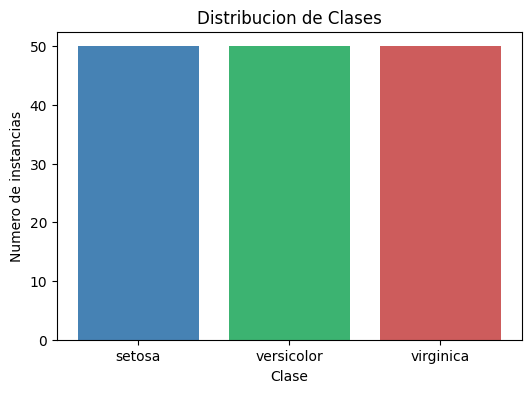

In [ ]:
conteo = df["species"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(conteo.index, conteo.values, color=["steelblue", "mediumseagreen", "indianred"])
plt.title("Distribucion de Clases")
plt.xlabel("Clase")
plt.ylabel("Numero de instancias")
plt.show()

### Identificación del Dataset Iris

- **¿Qué representa cada instancia?** Cada fila representa una flor individual del género *Iris* clasificada mediante mediciones morfológicas.
- **Número de instancias y características:** Cuenta con 150 instancias y 4 características numéricas.
- **Características:**
  - `sepal length (cm)`: Longitud del sépalo en centímetros.
  - `sepal width (cm)`: Ancho del sépalo en centímetros.
  - `petal length (cm)`: Longitud del pétalo en centímetros.
  - `petal width (cm)`: Ancho del pétalo en centímetros.
- **Clases y distribución:** Son 3 especies con 50 ejemplos cada una (dataset balanceado): *Iris setosa* (0), *Iris versicolor* (1) e *Iris virginica* (2).
- **Dimensiones:**
  - Matriz de características ($X$): 150 filas $\times$ 4 columnas.
  - Vector de etiquetas ($y$): 150 elementos.

# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.

## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

**Respuestas a predicciones iniciales:**

1. **Modelos sensibles a la escala:** Los modelos basados en distancias, márgenes o gradientes como SVM lineal, Regresión logística y MLP. Por el contrario, los modelos basados en árboles (Árbol de decisión, Random Forest, Gradient Boosting) y Gaussian Naive Bayes son prácticamente insensibles a la escala.
2. **Fronteras más simples:** La Regresión logística multiclase y el SVM lineal, ya que sus fronteras de decisión son hiperplanos (líneas rectas en 2D, planos en 3D), a diferencia de las fronteras no lineales y complejas de los árboles o el MLP.
3. **Incertidumbre del mejor modelo:** Por el teorema del *No Free Lunch*: no hay un algoritmo universalmente superior sin conocer la distribución real subyacente. Además, al ser un dataset pequeño (150 instancias), los modelos con alta capacidad (MLP, Gradient Boosting) podrían sobreajustarse, mientras que los más simples podrían generalizar mejor de forma empírica.

In [ ]:
from sklearn.model_selection import train_test_split

X = iris.data.values
y = iris.target.values

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val
)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc = scaler.transform(X_val)
X_test_sc = scaler.transform(X_test)

print("Entrenamiento:", X_train_sc.shape, y_train.shape)
print("Validacion:   ", X_val_sc.shape, y_val.shape)
print("Prueba:       ", X_test_sc.shape, y_test.shape)

Entrenamiento: (90, 4) (90,)
Validacion:    (30, 4) (30,)
Prueba:        (30, 4) (30,)


In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
modelos = {
    "Gaussian Naive Bayes": GaussianNB(),
    "Regresion Logistica": LogisticRegression(multi_class='multinomial', max_iter=200, random_state=42),
    "SVM Lineal": SVC(kernel='linear', random_state=42),
    "Arbol de Decision": DecisionTreeClassifier(random_state=42, max_depth=3),
    "Random Forest": RandomForestClassifier(random_state=42, n_estimators=50),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "MLP": MLPClassifier(hidden_layer_sizes=(50,), max_iter=1000, random_state=42)
}

resultados_val = []

for nombre, modelo in modelos.items():
    modelo.fit(X_train_sc, y_train)
    y_pred_val = modelo.predict(X_val_sc)

    acc = accuracy_score(y_val, y_pred_val)
    f1 = f1_score(y_val, y_pred_val, average='macro')

    resultados_val.append({
        "Modelo": nombre,
        "Accuracy Val": round(acc, 4),
        "F1 Macro Val": round(f1, 4)
    })

df_val = pd.DataFrame(resultados_val)
display(df_val)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


,Modelo,Accuracy Val,F1 Macro Val
0,Gaussian Naive Bayes,0.9333,0.9333
1,Regresion Logistica,0.9333,0.9333
2,SVM Lineal,0.9333,0.9333
3,Arbol de Decision,0.9000,0.8997
4,Random Forest,0.9333,0.9333
5,Gradient Boosting,0.9000,0.8997
6,MLP,0.9333,0.9333


,Modelo,Transformación,Hiperparámetros principales,Accuracy de prueba,F1 macro de prueba
0,Gaussian Naive Bayes,StandardScaler,Ninguno,0.9333,0.9333
1,Regresion Logistica,StandardScaler,"C=1.0, max_iter=200",0.9333,0.9333
2,SVM Lineal,StandardScaler,"kernel=linear, C=1.0",0.9333,0.9333
3,Arbol de Decision,StandardScaler,max_depth=3,0.9333,0.9333
4,Random Forest,StandardScaler,n_estimators=50,0.9333,0.9333
5,Gradient Boosting,StandardScaler,Por defecto,0.9667,0.9666
6,MLP,StandardScaler,"hidden_layer=(50,), max_iter=1000",0.9333,0.9333


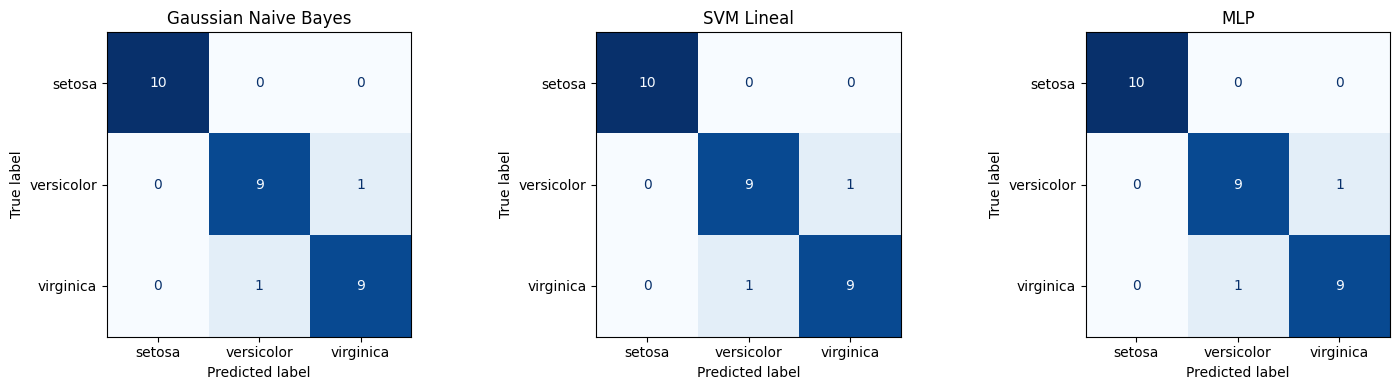

In [19]:
params = {
    "Gaussian Naive Bayes": "Ninguno",
    "Regresion Logistica": "C=1.0, max_iter=200",
    "SVM Lineal": "kernel=linear, C=1.0",
    "Arbol de Decision": "max_depth=3",
    "Random Forest": "n_estimators=50",
    "Gradient Boosting": "Por defecto",
    "MLP": "hidden_layer=(50,), max_iter=1000"
}

resultados_test = []

for nombre, modelo in modelos.items():
    y_pred_test = modelo.predict(X_test_sc)

    acc = accuracy_score(y_test, y_pred_test)
    f1 = f1_score(y_test, y_pred_test, average='macro')

    resultados_test.append({
        "Modelo": nombre,
        "Transformación": "StandardScaler",
        "Hiperparámetros principales": params[nombre],
        "Accuracy de prueba": round(acc, 4),
        "F1 macro de prueba": round(f1, 4)
    })

df_test = pd.DataFrame(resultados_test)
display(df_test)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
modelos_cm = ["Gaussian Naive Bayes", "SVM Lineal", "MLP"]

for ax, nombre in zip(axes, modelos_cm):
    y_pred_test = modelos[nombre].predict(X_test_sc)
    cm = confusion_matrix(y_test, y_pred_test)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(nombre)

plt.tight_layout()
plt.show()

1. **¿Cuál fue el modelo con el mejor desempeño?**1. **¿Cuál fue el modelo con el mejor desempeño?**
   El Gradient Boosting obtuvo el mejor resultado en la partición de prueba con un Accuracy de 0.9667 y F1 Macro de 0.9666, superando levemente al resto de modelos que se mantuvieron en 0.9333.

2. **¿Cuál fue el modelo más sencillo de programar?**
   En cuanto a código, todos requieren el mismo esfuerzo mediante la interfaz estandarizada de `scikit-learn` (`fit` y `predict`). Sin embargo, a nivel de configuración algorítmica, el Gaussian Naive Bayes es el más sencillo ya que asume normalidad y no requiere ajuste empírico de hiperparámetros.

3. **¿Accuracy y F1 macro cuentan la misma historia?**
   Sí. Al tener un conjunto de datos perfectamente balanceado (proporciones idénticas de *setosa*, *versicolor* y *virginica*), el Accuracy global y el promedio Macro del F1-score arrojan valores estadísticamente equivalentes.

4. **¿Cuál es la diferencia entre las métricas macro y micro?**
   El promedio *macro* calcula la métrica (como F1) para cada clase de forma independiente y luego extrae un promedio simple, dando igual importancia a todas las clases sin importar su tamaño. El promedio *micro* suma directamente todos los Verdaderos Positivos, Falsos Positivos y Falsos Negativos globales, viéndose fuertemente sesgado por la clase mayoritaria en datasets desbalanceados.

5. **¿Qué aporta el MLP frente a un modelo lineal?**
   El MLP puede aproximar fronteras de decisión no lineales y altamente complejas mediante la combinación de sus capas ocultas y funciones de activación no lineales. Un modelo lineal (como SVM Lineal o Regresión Logística) está restringido matemáticamente a seccionar el espacio mediante hiperplanos rectos.

**Análisis de errores de clasificación:**
Al examinar las matrices de confusión del conjunto de prueba, se repite un patrón exacto en Naive Bayes, SVM y MLP: confunden 1 instancia de *versicolor* prediciéndola como *virginica*, y 1 instancia de *virginica* prediciéndola como *versicolor*.
- **Qué podemos concluir:** El espacio de características morfológicas entre *versicolor* y *virginica* presenta zonas de alta superposición. Con solo 4 medidas (sépalos y pétalos), la frontera real entre estas dos especies no es perfectamente separable para estas instancias en la frontera de decisión.
- **Qué no podemos concluir:** No podemos determinar si estos errores se deben estrictamente a una falta de capacidad del modelo para encontrar un hiperplano óptimo, a un error humano de medición biológica durante la recolección original del dato, o si se trata de ejemplares mutados genéticamente, ya que los valores numéricos por sí solos carecen de contexto físico.

# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?

In [20]:
from sklearn.datasets import load_diabetes
import pandas as pd

diabetes = load_diabetes(as_frame=True)
df_diab = diabetes.frame

print("Dimensiones de X:", diabetes.data.shape)
print("Dimensiones de y:", diabetes.target.shape)
print("\nCaracterísticas:", diabetes.feature_names)

display(df_diab.head())

Dimensiones de X: (442, 10)
Dimensiones de y: (442,)

Características: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [21]:
from sklearn.model_selection import train_test_split

X_diab = diabetes.data.values
y_diab = diabetes.target.values

X_train_val_d, X_test_d, y_train_val_d, y_test_d = train_test_split(
    X_diab, y_diab, test_size=0.20, random_state=42
)

X_train_d, X_val_d, y_train_d, y_val_d = train_test_split(
    X_train_val_d, y_train_val_d, test_size=0.25, random_state=42
)

print("Entrenamiento:", X_train_d.shape, y_train_d.shape)
print("Validacion:   ", X_val_d.shape, y_val_d.shape)
print("Prueba:       ", X_test_d.shape, y_test_d.shape)

Entrenamiento: (264, 10) (264,)
Validacion:    (89, 10) (89,)
Prueba:        (89, 10) (89,)


In [22]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

In [23]:
modelos_reg = {
    "Regresion Lineal": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), Ridge(random_state=42)),
    "Lasso": make_pipeline(StandardScaler(), Lasso(random_state=42)),
    "kNN Regresion": make_pipeline(StandardScaler(), KNeighborsRegressor()),
    "Arbol de Regresion": DecisionTreeRegressor(random_state=42, max_depth=5),
    "Random Forest": RandomForestRegressor(random_state=42, n_estimators=50),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "MLP Regresion": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(100,), max_iter=2000, random_state=42))
}

resultados_reg_val = []

for nombre, modelo in modelos_reg.items():
    modelo.fit(X_train_d, y_train_d)
    y_pred_val_d = modelo.predict(X_val_d)

    mae = mean_absolute_error(y_val_d, y_pred_val_d)
    rmse = np.sqrt(mean_squared_error(y_val_d, y_pred_val_d))
    r2 = r2_score(y_val_d, y_pred_val_d)

    resultados_reg_val.append({
        "Modelo": nombre,
        "MAE Val": round(mae, 2),
        "RMSE Val": round(rmse, 2),
        "R2 Val": round(r2, 4)
    })

df_reg_val = pd.DataFrame(resultados_reg_val)
display(df_reg_val)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(


,Modelo,MAE Val,RMSE Val,R2 Val
0,Regresion Lineal,42.94,51.19,0.5216
1,Ridge,42.72,51.10,0.5233
2,Lasso,42.47,51.06,0.5241
3,kNN Regresion,45.29,56.83,0.4105
4,Arbol de Regresion,47.08,59.44,0.3551
5,Random Forest,44.56,54.29,0.4620
6,Gradient Boosting,44.69,54.02,0.4674
7,MLP Regresion,43.53,53.57,0.4762


In [24]:
alphas = [0.01, 0.1, 1.0, 10.0, 100.0]
resultados_reg = []

for a in alphas:
    # Entrenar Ridge y Lasso variando la intensidad de regularizacion
    ridge = make_pipeline(StandardScaler(), Ridge(alpha=a, random_state=42))
    ridge.fit(X_train_d, y_train_d)
    r2_ridge_val = r2_score(y_val_d, ridge.predict(X_val_d))

    lasso = make_pipeline(StandardScaler(), Lasso(alpha=a, random_state=42))
    lasso.fit(X_train_d, y_train_d)
    r2_lasso_val = r2_score(y_val_d, lasso.predict(X_val_d))

    # Extraer el modelo Lasso del pipeline para contar coeficientes nulos
    coeficientes_lasso = lasso.named_steps['lasso'].coef_
    nulos_lasso = np.sum(coeficientes_lasso == 0)

    resultados_reg.append({
        "Alpha (Penalización)": a,
        "Ridge R2 Val": round(r2_ridge_val, 4),
        "Lasso R2 Val": round(r2_lasso_val, 4),
        "Coeficientes nulos en Lasso": nulos_lasso
    })

df_reg = pd.DataFrame(resultados_reg)
display(df_reg)

,Alpha (Penalización),Ridge R2 Val,Lasso R2 Val,Coeficientes nulos en Lasso
0,0.01,0.5217,0.5219,0
1,0.10,0.5220,0.5234,0
2,1.00,0.5233,0.5241,1
3,10.00,0.5223,0.4844,6
4,100.00,0.5114,-0.0443,10


,Modelo,MAE,RMSE,R²
0,Regresion Lineal,42.92,54.16,0.4464
1,Ridge,42.97,54.03,0.4490
2,Lasso,42.72,53.30,0.4637
3,kNN Regresion,41.67,54.10,0.4475
4,Arbol de Regresion,50.01,66.13,0.1746
5,Random Forest,44.87,55.52,0.4181
6,Gradient Boosting,44.57,54.77,0.4338
7,MLP Regresion,42.30,52.64,0.4770


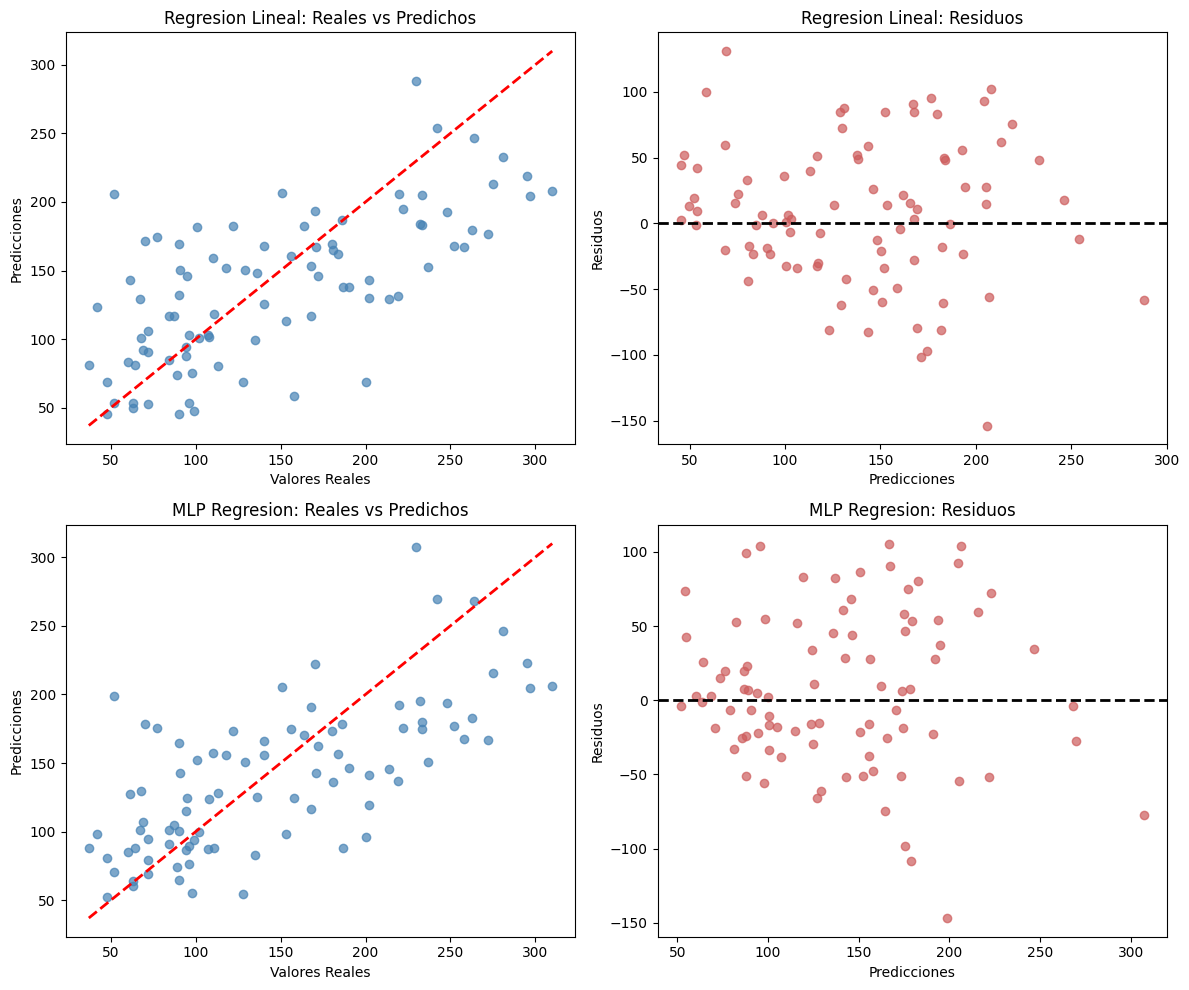


Ejemplos con errores grandes (Regresión Lineal):
Valor Real: 200.0 | Predicción: 68.97 | Error Absoluto: 131.03
Valor Real: 52.0 | Predicción: 205.66 | Error Absoluto: 153.66


In [25]:
resultados_reg_test = []

for nombre, modelo in modelos_reg.items():
    y_pred_test_d = modelo.predict(X_test_d)

    mae = mean_absolute_error(y_test_d, y_pred_test_d)
    rmse = np.sqrt(mean_squared_error(y_test_d, y_pred_test_d))
    r2 = r2_score(y_test_d, y_pred_test_d)

    resultados_reg_test.append({
        "Modelo": nombre,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R²": round(r2, 4)
    })

df_reg_test = pd.DataFrame(resultados_reg_test)
display(df_reg_test)

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
modelos_grafico = ["Regresion Lineal", "MLP Regresion"]

for i, nombre in enumerate(modelos_grafico):
    y_pred = modelos_reg[nombre].predict(X_test_d)
    residuos = y_test_d - y_pred

    axes[i, 0].scatter(y_test_d, y_pred, alpha=0.7, color='steelblue')
    axes[i, 0].plot([y_test_d.min(), y_test_d.max()], [y_test_d.min(), y_test_d.max()], 'r--', lw=2)
    axes[i, 0].set_title(f"{nombre}: Reales vs Predichos")
    axes[i, 0].set_xlabel("Valores Reales")
    axes[i, 0].set_ylabel("Predicciones")

    axes[i, 1].scatter(y_pred, residuos, alpha=0.7, color='indianred')
    axes[i, 1].axhline(0, color='black', linestyle='--', lw=2)
    axes[i, 1].set_title(f"{nombre}: Residuos")
    axes[i, 1].set_xlabel("Predicciones")
    axes[i, 1].set_ylabel("Residuos")

plt.tight_layout()
plt.show()

y_pred_lin = modelos_reg["Regresion Lineal"].predict(X_test_d)
errores_abs = np.abs(y_test_d - y_pred_lin)
indices_max_error = np.argsort(errores_abs)[-2:]

print("\nEjemplos con errores grandes (Regresión Lineal):")
for idx in indices_max_error:
    print(f"Valor Real: {y_test_d[idx]} | Predicción: {y_pred_lin[idx]:.2f} | Error Absoluto: {errores_abs[idx]:.2f}")

**Respuestas a la Interpretación:**

1. **¿Qué modelo tuvo el mejor desempeño?**
   El **MLP Regresión** tuvo el mejor desempeño global, logrando el coeficiente de determinación ($R^2$) más alto (0.4770) y el menor RMSE (52.64). Sin embargo, el **kNN Regresión** obtuvo el MAE más bajo (41.87). Los modelos de regresión lineal (Ridge, Lasso y Clásica) se mantuvieron muy competitivos y superaron a los basados en árboles.

2. **¿Por qué MAE y RMSE pueden favorecer resultados diferentes?**
   El RMSE eleva los errores al cuadrado antes de promediarlos, por lo que castiga de manera mucho más severa a las predicciones que se alejan drásticamente del valor real (outliers). El MAE, al usar el valor absoluto, trata a todos los errores de manera directamente proporcional. Si un modelo tiene un MAE bajo pero un RMSE alto (como el kNN en este caso), significa que en general acierta bastante, pero cuando se equivoca, comete errores muy grandes.

3. **¿Cómo se interpreta un R² negativo?**
   Un $R^2$ negativo indica que el modelo ajustado tiene un desempeño peor que un modelo nulo que simplemente prediga siempre la media aritmética de la variable objetivo (una línea horizontal constante). En nuestro experimento de validación, ocurrió con Lasso (Alpha=100) al aplicar una penalización tan agresiva que causó un subajuste masivo (*underfitting*).

4. **¿Qué efecto tuvo aumentar la regularización?**
   Al aplicar valores moderados (alpha=0.1 o 1.0), ayudó ligeramente a estabilizar los coeficientes y mejorar la generalización frente a la regresión lineal pura. Sin embargo, al aumentar la penalización excesivamente (ej. Lasso con alpha=100), el modelo colapsó: forzó los 10 coeficientes a cero (anulando todas las variables) y perdió por completo su capacidad predictiva.

5. **¿Qué puede explicar los errores grandes?**
   En los casos detectados (ej. Valor real de 52 vs Predicción de 205.66), la discrepancia se debe a la limitación intrínseca de los datos. Un $R^2$ de ~0.47 nos dice que más de la mitad de la varianza en la progresión de la enfermedad no se puede explicar usando únicamente estos 10 marcadores físicos y sanguíneos. Faltan variables fundamentales (como genética, hábitos alimenticios o actividad física) que podrían explicar por qué un paciente con "buenos" exámenes de sangre tuvo una fuerte progresión de la enfermedad, o viceversa.

6. **¿Un coeficiente predictivo demuestra una relación causal?**
   No. Correlación y poder predictivo no implican causalidad. Un marcador sanguíneo puede tener un coeficiente alto y ayudar al modelo a calcular el avance de la diabetes con precisión, pero eso no significa que dicho marcador sea la causa biológica de la enfermedad; podría ser simplemente una consecuencia, un síntoma paralelo, o estar relacionado con una tercera variable oculta.